In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import optuna
from scipy import sparse

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [3]:
import random
def giniTest(y, py):
    data = pd.DataFrame({"y":y, "py":py})
    random.seed(1)
    n = len(y)
    data['rand_unif'] = np.random.uniform(0.0, 1.0, size = len(y))
    sorted_y = data.iloc[np.argsort(data.py, order = data.rand_unif), 0]
    i = np.array(range(1, n+1))
    giniIndex = 1-2/(n-1)*(n-sum(sorted_y*i)/sum(sorted_y))
    return giniIndex


def mae(y, py):
    MAE = None
    MAE = sum(abs(y-py))/len(y)
    return MAE

def rmse(y, py):
    RMSE = None
    RMSE = (sum((y-py)**2)/len(y))**0.5
    return RMSE

def pe(y, py):
    PE = None
    PE = (sum(y)-sum(py))/sum(y)
    return PE


def PredictionError(y, py):
    pre = [giniTest(y,py), pe(y,py), rmse(y, py), mae(y,py)]
    rounding = [round(i, 2) for i in pre]
    return rounding

## Optuna tuning loading

In [4]:
prefix = "lgbm_1000_"
coverage = ["BG"]
metric = ["mae"]
trialname_list = []
# set trial names
for _cov in coverage :
    for _metric in metric:
        trialname_list.append(prefix + _cov + "_" + _metric)

# load trials
trial_list = []
for trial_name in trialname_list :
    storage_name = "sqlite:///{}.db".format(trial_name)
    trial_list.append(optuna.load_study(study_name=trial_name, storage=storage_name))

trial_result = [trial.trials_dataframe() for trial in trial_list]

## Data loading

In [ ]:
train = pd.read_csv("BG_embedding/train_BG.csv")
test = pd.read_csv("BG_embedding/test_BG_3.csv")

train['ObsAnnualizedLoss'] = train['ObsAnnualizedLoss'].apply(lambda x: min(x, 1e5))
train['ModAnnualizedLoss'] = train['ModAnnualizedLoss'].apply(lambda x: min(x, 1e5))
test['ObsAnnualizedLoss'] = test['ObsAnnualizedLoss'].apply(lambda x: min(x, 1e5)) 
test['ModAnnualizedLoss'] = test['ModAnnualizedLoss'].apply(lambda x: min(x, 1e5)) 
    
y_train = train['ObsAnnualizedLoss']
X_train = train.drop(columns = ['REC_ID', 'CLIENT_ID', 'ModAnnualizedLoss', 'ObsAnnualizedLoss'])

y_test = test['ObsAnnualizedLoss']
X_test = test.drop(columns = ['REC_ID', 'CLIENT_ID', 'ModAnnualizedLoss', 'ObsAnnualizedLoss'])

x_train_sparse = sparse.csr_matrix(X_train) 
train_set = lgb.Dataset(x_train_sparse, y_train.values.ravel(), free_raw_data=False)

In [6]:
# retrieve best trial
for trialname, trial in zip(trialname_list, trial_list) :
    # get best trials by trialname
    if "BG" in trialname and "mae" in trialname :
         best_trials_mae = trial.best_trials

best_param_mae = best_trials_mae[0].params

best_param_mae["early_stopping_rounds"] = 200
best_param_mae["force_row_wise"] = True
best_param_mae

{'feature_fraction': 0.20623834580510791,
 'learning_rate': 0.005038250439499633,
 'max_depth': 31,
 'min_child_samples': 80,
 'num_leaves': 90,
 'reg_alpha': 0.9421299978100052,
 'reg_lambda': 0.9404697484569013,
 'subsample': 0.9831979717911505,
 'subsample_for_bin': 60000,
 'early_stopping_rounds': 200,
 'force_row_wise': True}

### First time model training

In [7]:
## For MAE model
# To retrieve the best_n_estimators_mae
cv_results = lgb.cv(best_param_mae, train_set, num_boost_round=1000, nfold = 10,
                        #mse mae
                        metrics = 'mae',
                        stratified=False ,seed=0)

best_n_estimators_mae = int(np.argmin(cv_results['valid l1-mean']) )
best_score_mae = np.min(cv_results['valid l1-mean'])

# early stopping rounds require a evaluation set for training
del best_param_mae["early_stopping_rounds"]
reg_bg = lgb.LGBMRegressor(n_estimators = best_n_estimators_mae, n_jobs = -1, random_state = 50, **best_param_mae)
reg_bg.fit(train_set.data, train_set.label)

[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 70713, number of used features: 420
[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 70713, number of used features: 420
[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 70713, number of used features: 420
[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 70713, number of used features: 420
[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 70713, number of used features: 420
[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 70713, number of used features: 420
[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 70713, number of used features: 420
[LightGBM] [Info] Total Bins 21022
[LightGBM] [Info] Number of data points in the train set: 7071

,boosting_type,'gbdt'
,num_leaves,90
,max_depth,31
,learning_rate,0.005038250439499633
,n_estimators,839
,subsample_for_bin,60000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,80


In [8]:
# import joblib
# # # save model
# joblib.dump(reg_bg, "InsurTech_bg_embedding.pkl")

### Reproducible model loading

In [10]:
import joblib
# reg_bg = joblib.load("InsurTech_bg_embedding.pkl")
reg_bg_clustering = joblib.load("InsurTech_bg.pkl")

## Evaluation

In [ ]:
# Obtaining predictions
pred_train_embedding = reg_bg.predict(X_train)
train_pred_df_embedding = pd.concat([train[["REC_ID", "ObsAnnualizedLoss", "ModAnnualizedLoss"]], pd.Series(pred_train_embedding)], ignore_index = True, axis = 1)\
    .rename(columns = {0: "REC_ID", 1 : 'ObsAnnualizedLoss', 2: "ModAnnualizedLoss", 3: 'pred_train'}).reset_index(drop = True)
pred_test_embedding = reg_bg.predict(X_test)
test_pred_df_embedding = pd.concat([test[["REC_ID", "ObsAnnualizedLoss", "ModAnnualizedLoss"]], pd.Series(pred_test_embedding)], ignore_index = True, axis = 1)\
    .rename(columns = {0: "REC_ID", 1 : 'ObsAnnualizedLoss', 2: "ModAnnualizedLoss", 3: 'pred_test'}).reset_index(drop = True)

# Load original data
train_clustering = pd.read_csv("BG_clustering/train_BG.csv")
test_clustering = pd.read_csv("BG_clustering/test_BG_3.csv")

train_clustering['ObsAnnualizedLoss'] = train_clustering['ObsAnnualizedLoss'].apply(lambda x: min(x, 1e5))
train_clustering['ModAnnualizedLoss'] = train_clustering['ModAnnualizedLoss'].apply(lambda x: min(x, 1e5))
test_clustering['ObsAnnualizedLoss'] = test_clustering['ObsAnnualizedLoss'].apply(lambda x: min(x, 1e5)) 
test_clustering['ModAnnualizedLoss'] = test_clustering['ModAnnualizedLoss'].apply(lambda x: min(x, 1e5)) 
    
y_train_clustering = train_clustering['ObsAnnualizedLoss']
X_train_clustering = train_clustering.drop(columns = ['REC_ID', 'CLIENT_ID', 'ModAnnualizedLoss', 'ObsAnnualizedLoss'])

y_test_clustering = test_clustering['ObsAnnualizedLoss']
X_test_clustering = test_clustering.drop(columns = ['REC_ID', 'CLIENT_ID', 'ModAnnualizedLoss', 'ObsAnnualizedLoss'])

# Obtaining predictions
pred_train_clustering = reg_bg_clustering.predict(X_train_clustering)
train_pred_df_clustering = pd.concat([train_clustering[["REC_ID", "ObsAnnualizedLoss", "ModAnnualizedLoss"]], pd.Series(pred_train_clustering)], ignore_index = True, axis = 1)\
    .rename(columns = {0: "REC_ID", 1 : 'ObsAnnualizedLoss', 2: "ModAnnualizedLoss", 3: 'pred_train'}).reset_index(drop = True)
pred_test_clustering = reg_bg_clustering.predict(X_test_clustering)
test_pred_df_clustering = pd.concat([test_clustering[["REC_ID", "ObsAnnualizedLoss", "ModAnnualizedLoss"]], pd.Series(pred_test_clustering)], ignore_index = True, axis = 1)\
    .rename(columns = {0: "REC_ID", 1 : 'ObsAnnualizedLoss', 2: "ModAnnualizedLoss", 3: 'pred_train'}).reset_index(drop = True)


[LightGBM] [Warning] feature_fraction is set=0.20623834580510791, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.20623834580510791
[LightGBM] [Warning] feature_fraction is set=0.20623834580510791, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.20623834580510791


In [ ]:
from prettytable import PrettyTable
table = PrettyTable(["Tunning metric", "GINI", "PE", "RMSE", "MAE"])
table.title = 'LGBM MAE Training'
table.add_row(['ModAnnualizedLoss'] + PredictionError(train_pred_df_embedding["ObsAnnualizedLoss"], train_pred_df_embedding["ModAnnualizedLoss"]))
table.add_row(['LGBM + category clustering'] + PredictionError(train_pred_df_clustering["ObsAnnualizedLoss"], train_pred_df_clustering["pred_train"]))
table.add_row(['LGBM + category embedding'] + PredictionError(train_pred_df_embedding["ObsAnnualizedLoss"], train_pred_df_embedding["pred_train"]))
print(table)
table = PrettyTable(["Tunning metric", "GINI", "PE", "RMSE", "MAE"])
table.title = 'LGBM MAE Test'
table.add_row(['ModAnnualizedLoss'] + PredictionError(test_pred_df_embedding["ObsAnnualizedLoss"], test_pred_df_embedding["ModAnnualizedLoss"]))
table.add_row(['LGBM + category clustering'] + PredictionError(test_pred_df_clustering["ObsAnnualizedLoss"], test_pred_df_clustering["pred_test"]))
table.add_row(['LGBM + category embedding'] + PredictionError(test_pred_df_embedding["ObsAnnualizedLoss"], test_pred_df_embedding["pred_test"]))
print(table)

/tmp/ipykernel_1954220/1439545566.py:23: FutureWarning: The provided callable <function mean at 0xffff5c15b740> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  Result = pd.pivot_table(LocalDF[['bin','actual','old','new']],index=["bin"],values=["actual","old","new"],aggfunc=np.mean).reset_index(drop=True)


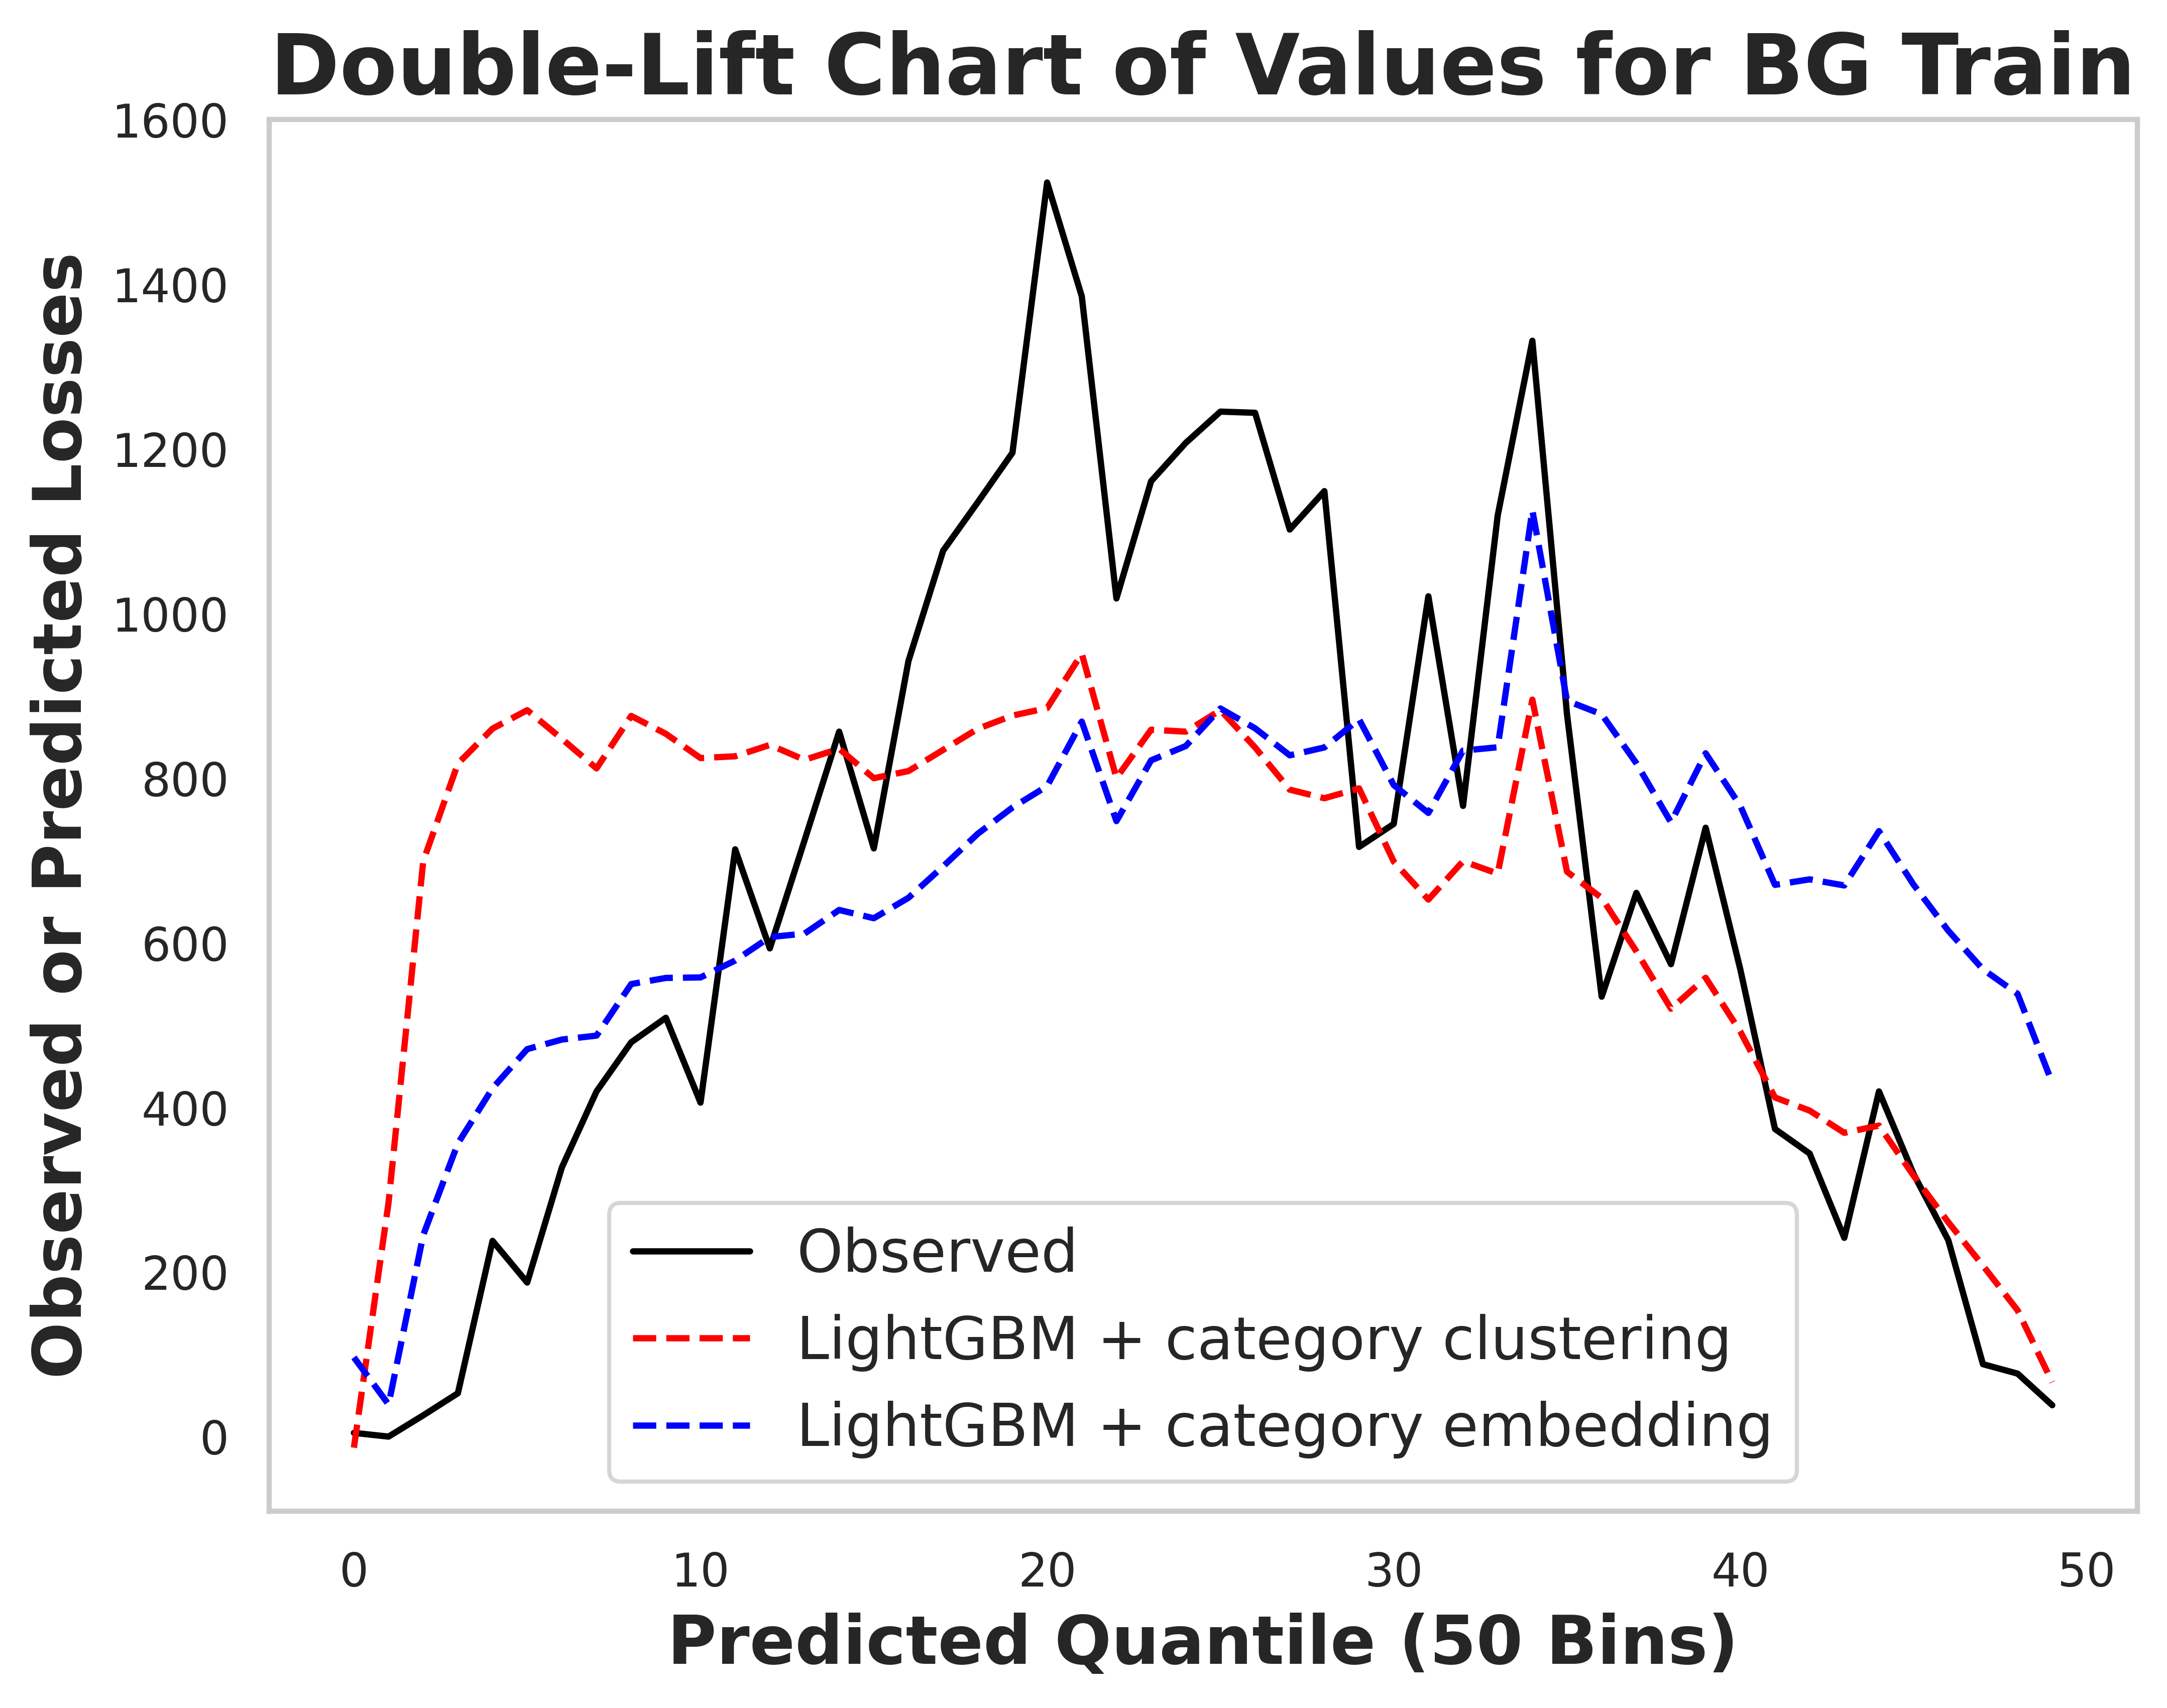

In [26]:
# Double Lift chart
def getDoubleLiftChart(Actual, Old, New, Dislocation, NumBins=5, LossRatio=False):
    # Convert input values to a Pandas dataframe
    LocalDF = pd.DataFrame({'actual':Actual,'old':Old,'new':New,'dislocation':Dislocation})
    # Determine size of dataframe
    DfSize = float(len(LocalDF))
    # Determine size of each bin
    BinSize = float(100)/NumBins
    # Construct raking using predicted values
    LocalDF['ranking'] = LocalDF['dislocation'].rank()
    # Sort data based on ranking
    LocalDF = LocalDF.sort_values(['ranking'], ascending=[True]).reset_index(drop=True)
    # Determine percentile
    LocalDF['percentile'] = LocalDF.index
    LocalDF['percentile'] = LocalDF['percentile'].apply(lambda X: math.ceil(100. * float(X+1) / DfSize))
    LocalDF['bin'] = LocalDF['percentile'].apply(lambda X: math.ceil(X/BinSize))
    # Construct pivot containing average actual and predicted value per bin
    if LossRatio:
        Result = pd.pivot_table(LocalDF[['bin','actual','old','new']],index=["bin"],values=["actual","old","new"],aggfunc=np.sum).reset_index(drop=True)
        for CurCol in ['old','new']:
            Result[CurCol] = Result['actual']/Result[CurCol]
    else:
        Result = pd.pivot_table(LocalDF[['bin','actual','old','new']],index=["bin"],values=["actual","old","new"],aggfunc=np.mean).reset_index(drop=True)
    return Result

def plotDoubleLiftChart(Actual, Old, New, Dislocation, NumBins, ChartTitle='Title Not Specified', LossRatio=False):
    # Initialize plot
    plt.figure(figsize =(8, 6))
    # Retrieve double-lift chart
    LiftChart = getDoubleLiftChart(Actual, Old, New, Dislocation, NumBins=NumBins, LossRatio=LossRatio)
    # Specify title and labels for each axis
    plt.title(ChartTitle, fontsize = 20, fontweight='bold')
    plt.xlabel("Predicted Quantile (%s Bins)" % (NumBins), fontsize = 16, fontweight='bold')
    plt.ylabel("Observed or Predicted Losses", fontsize = 16, fontweight='bold')
    if LossRatio:
        plt.plot(LiftChart['old'], label = 'Old Ratio', color = 'red', ls = 'solid')
        plt.plot(LiftChart['new'], label = 'New Ratio', color = 'green', ls = 'dashed')
    else:
        plt.plot(LiftChart['actual'], label = 'Actual', color = 'black', ls = 'solid', linewidth = 1.5)
        plt.plot(LiftChart['old'], label = 'Old', color = 'red', ls = 'dashed',  linewidth = 1.5)
        plt.plot(LiftChart['new'], label = 'New', color = 'blue', ls = 'dashed', linewidth = 1.5)
        
plotDoubleLiftChart(
    Actual = train_pred_df_clustering["ObsAnnualizedLoss"], 
    Old = train_pred_df_clustering["pred_train"], 
    New = train_pred_df_embedding["pred_train"], 
    Dislocation = train_pred_df_embedding["pred_train"] / train_pred_df_clustering["pred_train"] - 1, 
    NumBins = 50, ChartTitle='Double-Lift Chart of Values for BG Train', LossRatio=False)
sns.set_theme(style="whitegrid")
plt.grid(False)
plt.legend(labels=["Observed","LightGBM + category clustering", "LightGBM + category embedding"], fontsize = 14)
plt.savefig("dl_bg.pdf")
plt.show()

/tmp/ipykernel_1954220/3735307372.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gini_fi_25['feature']=gini_fi_25.feature.map(rename_dict)


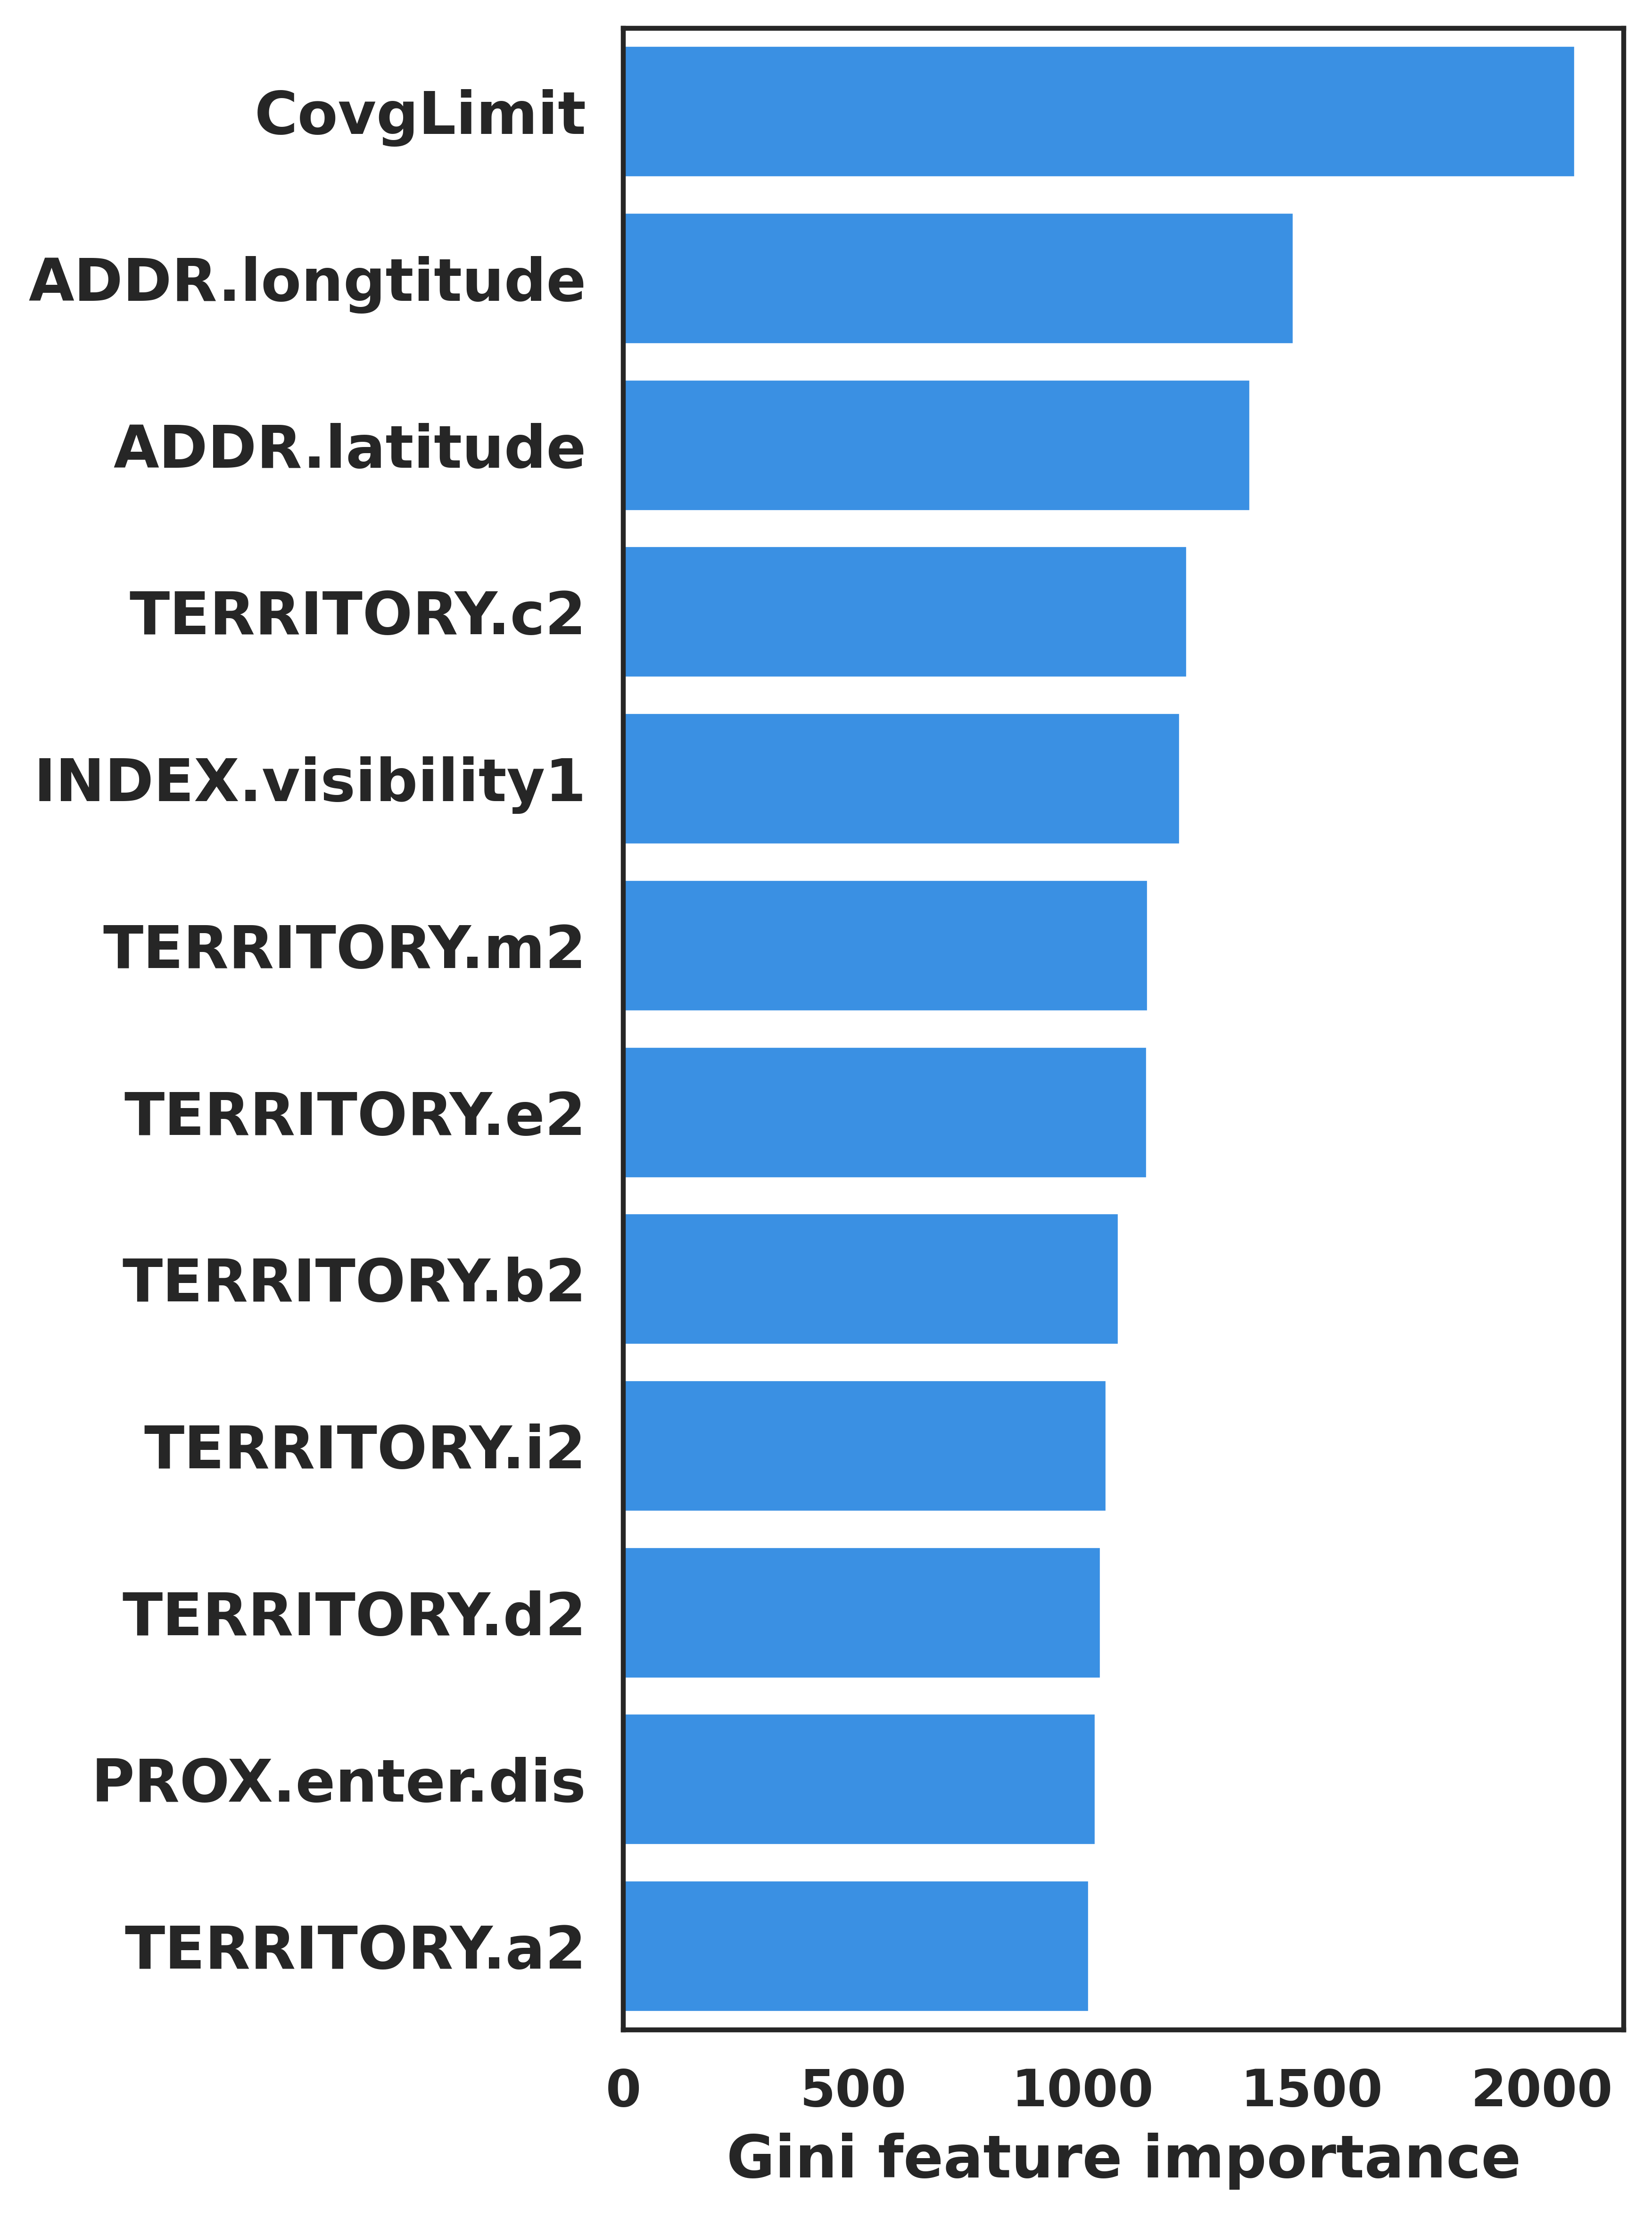

In [ ]:
# Feature importance
import matplotlib as mpl

gini_fi = pd.DataFrame({'feature':X_test.columns,
                        'importance':reg_bg.feature_importances_})
gini_fi_s = gini_fi.sort_values(by = 'importance', ascending=False)
gini_fi_25 = gini_fi_s.iloc[0:25]

mpl.rcParams['figure.dpi'] = 600
sns.set_style("white")
plt.figure(figsize = (6, 8))

ax = sns.barplot(data = gini_fi_25,
            y='feature',
            x='importance',            
            orient = 'h',
            color = 'dodgerblue'
           )

ax.set_xlabel("Gini feature importance", fontsize = 15, fontweight='bold')
ax.set_ylabel("")
plt.xticks(fontsize=13, fontweight='bold')
plt.yticks(fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("gini_bg.pdf")
plt.show()